In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
from scipy import optimize 
import hunter2024mwmodel as h2024
import barframe
agama.setUnits(length=1, mass=1, velocity=1)

In [2]:
bar1=h2024.coleman2020(**h2024.coleman_components)
bar2=h2024.portail_component(**h2024.portail_bar_1)
bar3=h2024.portail_component(**h2024.portail_bar_2)    
pbar1   = agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar2   = agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar3   = agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar = pbar1+pbar2+pbar3

In [3]:
# the rest of the potetial 
psagA   = agama.Potential(**h2024.supermassiveblackhole)
pnsc    = agama.Potential(**h2024.nsc)
pnsd1   = agama.Potential(**h2024.NSD1,)
pnsd2   = agama.Potential(**h2024.NSD2)
pdisk1  = agama.Potential(**h2024.DISK1)
pdisk2  = agama.Potential(**h2024.DISK2)
pgdisk1 = agama.Potential(**h2024.GDISK1)
pgdisk2 = agama.Potential(**h2024.GDISK2)
phalo   = agama.Potential(**h2024.EINASTO)
pot_total=agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)

In [4]:
methods=list(dir(pbar))
methodss=[]
for x in methods:
    if x[0]!="_":
        methodss.append(x)
methodss

['Rcirc',
 'Rmax',
 'Rperiapo',
 'Tcirc',
 'density',
 'enclosedMass',
 'eval',
 'export',
 'force',
 'forceDeriv',
 'potential',
 'principalAxes',
 'projectedDensity',
 'projectedEval',
 'sample',
 'totalMass']

- Sample positions randomly within the first lagrange point
- Then, using the jacobii energy, get an isotropic velocity at that point...

In [25]:
omega = -37.5
x_l1 = barframe.xL1(pot_total, omega)
y_l4 = barframe.yL4(pot_total,omega)
e_l1 = barframe.pot_eff(pot_total, omega, numpy.array([x_l1, 0.0, 0.0]))
e_0  = barframe.pot_eff(pot_total, omega, numpy.array([0.0, 0.0, 0.0]))
e_l4 = barframe.pot_eff(pot_total,omega,numpy.array([0,y_l4,0]))

# make anonymous function for the crossing
y_max_within_bar_given_x_minimize = lambda y, x, pot, omega: -(barframe.pot_eff(pot,omega,numpy.column_stack([numpy.abs(numpy.array(x)),numpy.array(y),0*numpy.array(y)])))
# now find the maxmimum allowed y given an energy 
y_max_root_within_bar_given_x = lambda y, x, pot, omega, Ej: barframe.pot_eff(pot,omega,numpy.array([x,y,0])) - Ej
# now get the whole zero velocity curve in the y-z plane!
z_max_within_bar_given_x_y = lambda z, x, y, pot, omega, Ej: barframe.pot_eff(pot,omega,numpy.array([x,y,z])) - Ej


In [92]:
# get the 3D zero velocity surface for the effective potential. 
# sample it in order 
x_sample = numpy.random.uniform(-x_l1, x_l1)

# since the curvatuce changes, and `brentq` looks for roots within a,b, I have to refine the bounds on y
solution=optimize.minimize(y_max_within_bar_given_x_minimize,x_l1/2,args=(x_sample,pot_total,omega))

y_max = optimize.brentq(y_max_root_within_bar_given_x,0,solution.x[0],args=(x_sample,pot_total,omega,e_l1))
y_sample = numpy.random.uniform(-y_max,y_max)
# given y, get the maximum z
# update the energy, because, it's not the lagrange enegy, it's less! 
e_at_x_y = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,y_sample,0]))
z_max = optimize.brentq(z_max_within_bar_given_x_y,0,y_max,args=(x_sample,y_sample,pot_total,omega,e_l1))
z_sample = numpy.random.uniform(-z_max,z_max)

remaining speed?

In [107]:
maxspeed = numpy.sqrt(-2*(barframe.pot_eff(pot_total,omega,numpy.array([0.1,0.1,0.1])) - e_l1))
availablespeed = numpy.sqrt(-2*(barframe.pot_eff(pot_total,omega,numpy.array([x_sample,y_sample,z_sample])) - e_l1))
v_sample = numpy.random.uniform(0,availablespeed)
# for the uniform circle, it's uniform over cosine
theta=numpy.arccos(numpy.random.uniform(-1,1))
phi = numpy.random.uniform(0,2*numpy.pi)
vx = v_sample*numpy.sin(theta)*numpy.cos(phi)
vy = v_sample*numpy.sin(theta)*numpy.sin(phi)
vz = v_sample*numpy.cos(theta)


Text(1.5, 0.6969023966812887, '$v_{\\mathrm{sampled}}$')

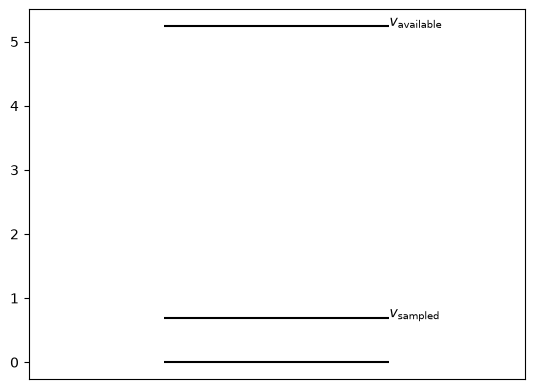

In [138]:
maxspeed
availablespeed

fig,axis=plt.subplots(1,1)
axis.eventplot([0,v_sample,availablespeed],orientation="vertical",color="k")
axis.set(xticks=[])
# axis.text(1.5, maxspeed,s=r"$v_{\mathrm{max}}$")
axis.text(1.5, availablespeed,s=r"$v_{\mathrm{available}}$",)
axis.text(1.5, v_sample,s=r"$v_{\mathrm{sampled}}$",)

aesthetics for the plot 

In [94]:
npoints=201
# get the zero velocity curve in the yz-plane
threshold = 1e-3
y_zvc = numpy.linspace(-(1-threshold)*y_max,(1-threshold)*y_max,npoints)
z_zvc = numpy.array([optimize.brentq(z_max_within_bar_given_x_y,0,y_max,args=(x_sample,yy,pot_total,omega,e_l1)) for yy in y_zvc])

# get the countour lines first 
xfactor,yfactor = 4, 1.2
xs,ys=numpy.linspace(-xfactor*x_l1,xfactor*x_l1,npoints),numpy.linspace(-yfactor*x_l1,yfactor*x_l1,npoints)
XS,YS = numpy.meshgrid(xs,ys)
pos=numpy.column_stack((XS.flatten(),YS.flatten(),0*YS.flatten()))
peff = barframe.pot_eff(pot_total,omega,pos)
pot_eff = numpy.reshape(peff,XS.shape)
contours = numpy.linspace(pot_eff.min(),pot_eff.max(),10)
# add teh special contours 
contours=numpy.concatenate((contours,numpy.linspace(e_l1*(1+.4e-3),e_l4,5)))
contours=numpy.sort(contours)

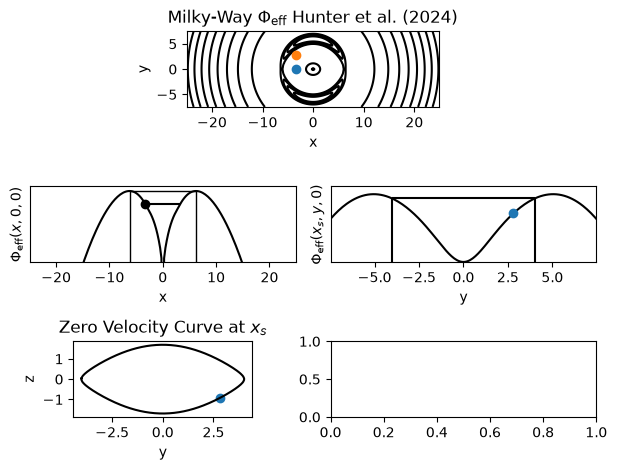

In [95]:
nrow,ncol=3,2
fig = plt.figure()
gs=matplotlib.gridspec.GridSpec(3,2,figure=fig)
axis=fig.add_subplot(gs[0,:])
axes = []
for i in range(1,nrow):
    axes.append([])
    for j in range(ncol):
        axes[i-1].append(fig.add_subplot(gs[i,j]))
axis.contour(XS,YS,pot_eff,levels=contours,colors="k",linestyle="-");
axis.set(aspect="equal",xlabel="x", ylabel="y",title=r"Milky-Way $\Phi_{\mathrm{eff}}$ Hunter et al. (2024)")
fig.tight_layout()

# now visualize sampling the x-position 
pos = numpy.column_stack([xs,xs*0,xs*0])
phi_x = barframe.pot_eff(pot_total,omega,pos)
phi_x_sample = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,0,0]))
phi_0 = barframe.pot_eff(pot_total,omega,numpy.array([0.1,0.1,0.1]))

# start the axes for the effective potential 
axes[0][0].set(xlabel="x", ylabel=r"$\Phi_{\mathrm{eff}}(x,0,0)$",yticks=[],xlim=[xs.min(),xs.max()],ylim=[phi_0,(1-3e-2)*phi_x.max()]);
# plot the effective potential at y=0
axes[0][0].plot(xs,phi_x,color="k")
# show the box that we'll be inside for picking an x_sample
axes[0][0].hlines(e_l1,-x_l1,x_l1,color="k",linewidth=1)
axes[0][0].vlines([-x_l1, x_l1],e_0,e_l1,color="k",linewidth=1)

# show the x_sample 
axes[0][0].hlines(phi_x_sample,-numpy.abs(x_sample),numpy.abs(x_sample),color="k")
axes[0][0].scatter(x_sample,barframe.pot_eff(pot_total,omega,numpy.array([x_sample,0,0])),color="k")
# show it on the main plot (maybe update it too)
mydot=axis.scatter(x_sample,0)

### START THE PLOT FOR SAMPLING y 
pos = numpy.column_stack((x_sample*numpy.ones_like(ys), ys,0*ys))
phi_y_at_x = barframe.pot_eff(pot_total,omega,pos)
phi_y_max_at_x = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,y_max,0]))
phi_y_max_at_x_sample = barframe.pot_eff(pot_total,omega,numpy.array([x_sample,y_sample,0]))
axes[0][1].set(ylabel=r"$\Phi_{\mathrm{eff}}(x_s,y,0)$",yticks=[],xlabel="y",xlim=[ys.min(),ys.max()],ylim=[phi_y_at_x.min(),(1-1e-2)*phi_y_at_x.max()]);
# show the slice in the effective potential 
axes[0][1].plot(ys,phi_y_at_x,color="k")
# show the limits 
axes[0][1].vlines([-y_max,y_max],phi_y_at_x.min(),phi_y_max_at_x,color="k" )
axes[0][1].hlines(e_l1,-y_max,y_max,color="k")

# add the updated point 
axes[0][1].scatter([y_sample], [phi_y_max_at_x_sample],zorder=10)
axis.scatter([x_sample],[y_sample],zorder=10)

axes[1][0].plot(numpy.concatenate((y_zvc, y_zvc[::-1],[y_zvc[0]])),numpy.concatenate((z_zvc,-z_zvc[::-1],[z_zvc[0]])),color="k")
axes[1][0].scatter(y_sample,z_sample)
axes[1][0].set(xlabel="y", ylabel="z", title=r"Zero Velocity Curve at $x_s$",aspect="equal")
fig.tight_layout()

In [96]:
# find the z_max for all spaces between -y_max and y_max given x_sample
